# Loading a Delivery Truck: Knapsack Problem with a Genetic Algorithm (PyGAD)

## 1. Install and import PyGAD

In [1]:
!pip install -q pygad

In [2]:
import itertools
import time
from typing import Any

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pygad

print('PyGAD version:', pygad.__version__)

PyGAD version: 3.7.0


## 2. Products and truck capacity

In [4]:
products = pd.DataFrame({
  'name': [
    'Refrigerator A', 'Cell phone', 'TV 55', "TV 50'", "TV 42'", 'Notebook A', 'Ventilator',
    'Microwave A', 'Microwave B', 'Microwave C', 'Refrigerator B', 'Refrigerator C', 'Notebook B', 'Notebook C',
  ],
  'space': [0.751, 0.00000899, 0.400, 0.290, 0.200, 0.00350, 0.496, 0.0424, 0.0544, 0.0319, 0.635, 0.870, 0.498, 0.527],
  'price': [999.90, 2199.12, 4346.99, 3999.90, 2999.00, 2499.90, 199.90, 308.66, 429.90, 299.29, 849.00, 1199.89, 1999.90, 3999.00],
})
products['price per m³'] = (products['price'] / products['space']).round(1)

SPACE_LIMIT = 3
spaces = products['space'].to_numpy()
prices = products['price'].to_numpy()
N_PRODUCTS = len(products)

print(f'{N_PRODUCTS} products, total space {spaces.sum():.3f} m³, total price {prices.sum():.2f}, truck limit {SPACE_LIMIT} m³')
products

14 products, total space 4.799 m³, total price 26330.35, truck limit 3 m³


,name,space,price,price per m³
0,Refrigerator A,0.751000,999.90,1331.4
1,Cell phone,0.000009,2199.12,244618465.0
2,TV 55,0.400000,4346.99,10867.5
3,TV 50',0.290000,3999.90,13792.8
4,TV 42',0.200000,2999.00,14995.0
5,Notebook A,0.003500,2499.90,714257.1
6,Ventilator,0.496000,199.90,403.0
7,Microwave A,0.042400,308.66,7279.7
8,Microwave B,0.054400,429.90,7902.6
9,Microwave C,0.031900,299.29,9382.1


In [7]:
all_solutions = np.array(list(itertools.product([0, 1], repeat=N_PRODUCTS)))
feasible = all_solutions[all_solutions @ spaces <= SPACE_LIMIT]
optimal_solution = feasible[np.argmax(feasible @ prices)]
OPTIMAL_VALUE = round(float(optimal_solution @ prices), 2)

print(f'Brute force over {len(all_solutions)} subsets, {len(feasible)} of them fit into the truck')
print(f'Optimal price: {OPTIMAL_VALUE}, space used: {optimal_solution @ spaces:.4f} m³')
print('Optimal products:', products.loc[optimal_solution == 1, 'name'].tolist())

Brute force over 16384 subsets, 12384 of them fit into the truck
Optimal price: 24281.55, space used: 2.9172 m³
Optimal products: ['Cell phone', 'TV 55', "TV 50'", "TV 42'", 'Notebook A', 'Microwave A', 'Microwave B', 'Microwave C', 'Refrigerator C', 'Notebook B', 'Notebook C']


## 3. Fitness function

In [10]:
def fitness_func(ga_instance: Any, solution: np.ndarray, solution_idx: int) -> float:
  total_space = float(np.dot(solution, spaces))
  total_price = float(np.dot(solution, prices))
  if total_space > SPACE_LIMIT:
    return 1.0

  return total_price

## 4. Initial population

In [14]:
SOL_PER_POP = 20


def make_initial_population(size: int, seed: int, fill_probability: float = 0.5) -> np.ndarray:
  rng = np.random.default_rng(seed)

  return (rng.random((size, N_PRODUCTS)) < fill_probability).astype(int)


initial_population = make_initial_population(SOL_PER_POP, seed=42)
initial_fitness = [fitness_func(None, solution, i) for i, solution in enumerate(initial_population)]

pd.DataFrame({
  'chromosome': [''.join(map(str, solution)) for solution in initial_population],
  'space': (initial_population @ spaces).round(4),
  'price': (initial_population @ prices).round(2),
  'fitness': initial_fitness,
}).head(10)

,chromosome,space,price,fitness
0,01001000111000,0.9213,6776.31,6776.31
1,11010001000111,2.9784,14706.37,14706.37
2,10001111111010,2.7122,10585.45,10585.45
3,01001101110000,0.3322,8735.87,8735.87
4,10110100000111,3.3395,19045.48,1.00
5,11011110000101,3.1375,18096.61,1.00
6,11011010111011,3.4833,17974.91,1.00
7,10001000111011,2.6973,11575.99,11575.99
8,10100010001111,4.1770,13594.58,1.00
9,11101001010101,2.8223,16351.85,16351.85


## 5. Genetic algorithm parameters

In [19]:
GA_PARAMS: dict[str, Any] = {
  'num_generations': 100,
  'num_parents_mating': 10,
  'fitness_func': fitness_func,
  'num_genes': N_PRODUCTS,
  'gene_space': [0, 1],
  'gene_type': int,
  'parent_selection_type': 'sss',
  'keep_parents': 2,
  'crossover_type': 'single_point',
  'crossover_probability': 0.9,
  'mutation_type': 'random',
  'mutation_percent_genes': 10,
  'suppress_warnings': True,
}

{key: value for key, value in GA_PARAMS.items() if key != 'fitness_func'}

{'num_generations': 100,
 'num_parents_mating': 10,
 'num_genes': 14,
 'gene_space': [0, 1],
 'gene_type': int,
 'parent_selection_type': 'sss',
 'keep_parents': 2,
 'crossover_type': 'single_point',
 'crossover_probability': 0.9,
 'mutation_type': 'random',
 'mutation_percent_genes': 10,
 'suppress_warnings': True}

## 6. Create and run the genetic algorithm

In [23]:
ga_instance = pygad.GA(initial_population=initial_population, random_seed=42, **GA_PARAMS)
ga_instance.run()

solution, solution_fitness, _ = ga_instance.best_solution()
print(f'Best fitness: {solution_fitness} (optimum {OPTIMAL_VALUE})')
print(f'Space: {solution @ spaces:.4f} m³ of {SPACE_LIMIT} m³')
print(f'Best solution found at generation {ga_instance.best_solution_generation}')
print('Products:', products.loc[solution == 1, 'name'].tolist())

Best fitness: 24281.550000000003 (optimum 24281.55)
Space: 2.9172 m³ of 3 m³
Best solution found at generation 32
Products: ['Cell phone', 'TV 55', "TV 50'", "TV 42'", 'Notebook A', 'Microwave A', 'Microwave B', 'Microwave C', 'Refrigerator C', 'Notebook B', 'Notebook C']


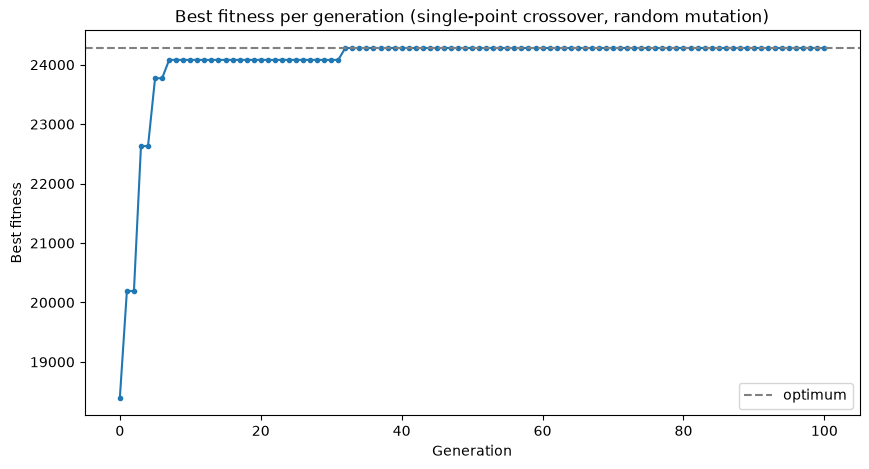

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(ga_instance.best_solutions_fitness, marker='.')
plt.axhline(OPTIMAL_VALUE, color='gray', linestyle='--', label='optimum')
plt.xlabel('Generation')
plt.ylabel('Best fitness')
plt.title('Best fitness per generation (single-point crossover, random mutation)')
plt.legend()
plt.show()

## 7. Influence of crossover and mutation types

In [45]:
CROSSOVER_TYPES = ['single_point', 'two_points', 'uniform', 'scattered']
MUTATION_TYPES = ['random', 'swap', 'inversion', 'scramble', 'adaptive']
SEEDS = range(20)


def run_ga(seed: int, **overrides: Any) -> pygad.GA:
  params = {**GA_PARAMS, **overrides}
  if params['mutation_type'] == 'adaptive' and 'mutation_percent_genes' not in overrides:
    params['mutation_percent_genes'] = (20, 5)
  population = make_initial_population(params.pop('sol_per_pop', SOL_PER_POP), seed)
  ga = pygad.GA(initial_population=population, random_seed=seed, **params)
  ga.run()

  return ga


def summarize_runs(runs: list[pygad.GA]) -> dict[str, float]:
  best = np.array([round(float(ga.best_solution()[1]), 2) for ga in runs])
  generations = np.array([ga.best_solution_generation for ga in runs])

  return {
    'optimum found, %': float(np.mean(best == OPTIMAL_VALUE) * 100),
    'mean best value': float(best.mean()),
    'worst best value': float(best.min()),
    'mean generation of best': float(generations.mean()),
  }


start = time.perf_counter()
operator_rows = []
for crossover_type in CROSSOVER_TYPES:
  for mutation_type in MUTATION_TYPES:
    runs = [run_ga(seed, crossover_type=crossover_type, mutation_type=mutation_type) for seed in SEEDS]
    operator_rows.append({'crossover': crossover_type, 'mutation': mutation_type, **summarize_runs(runs)})

operators = pd.DataFrame(operator_rows)
print(f'{len(operator_rows) * len(SEEDS)} GA runs in {time.perf_counter() - start:.1f} s')
operators.sort_values(['optimum found, %', 'mean generation of best'], ascending=[False, True]).round(2)

400 GA runs in 6.5 s


,crossover,mutation,"optimum found, %",mean best value,worst best value,mean generation of best
10,uniform,random,100.0,24281.55,24281.55,13.55
15,scattered,random,100.0,24281.55,24281.55,13.55
5,two_points,random,100.0,24281.55,24281.55,15.95
7,two_points,inversion,100.0,24281.55,24281.55,16.15
9,two_points,adaptive,100.0,24281.55,24281.55,17.55
12,uniform,inversion,100.0,24281.55,24281.55,18.85
17,scattered,inversion,100.0,24281.55,24281.55,18.85
14,uniform,adaptive,100.0,24281.55,24281.55,19.60
19,scattered,adaptive,100.0,24281.55,24281.55,19.60
4,single_point,adaptive,100.0,24281.55,24281.55,20.05


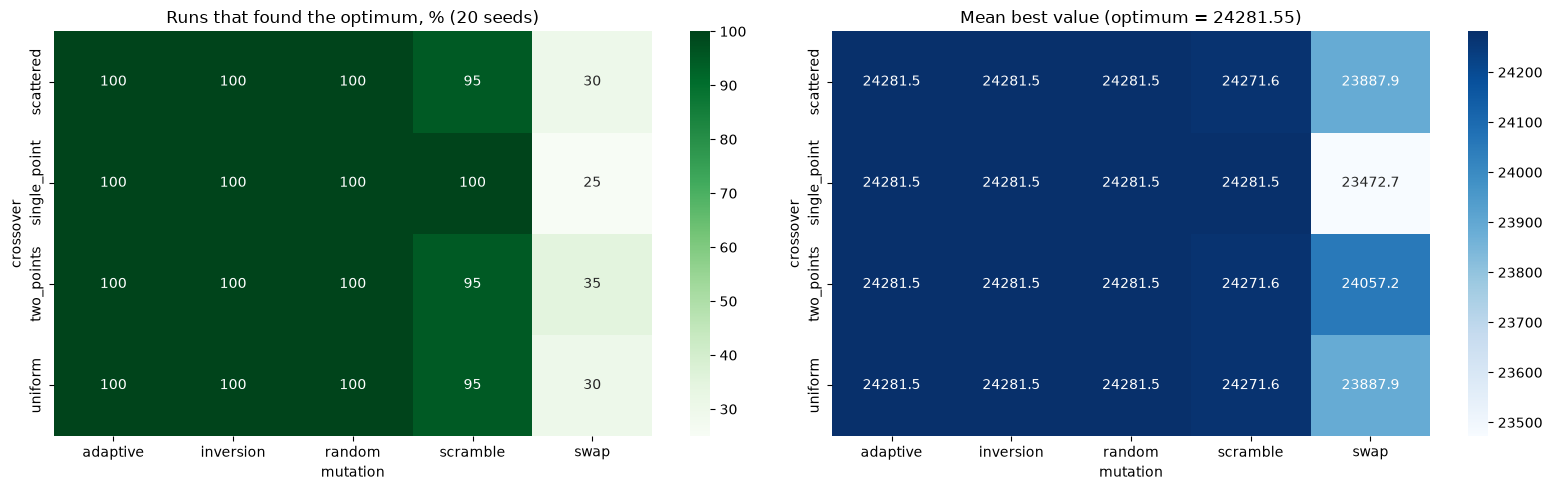

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(operators.pivot(index='crossover', columns='mutation', values='optimum found, %'),
            annot=True, fmt='.0f', cmap='Greens', ax=axes[0])
axes[0].set_title('Runs that found the optimum, % (20 seeds)')

sns.heatmap(operators.pivot(index='crossover', columns='mutation', values='mean best value'),
            annot=True, fmt='.1f', cmap='Blues', ax=axes[1])
axes[1].set_title(f'Mean best value (optimum = {OPTIMAL_VALUE})')

plt.tight_layout()
plt.show()

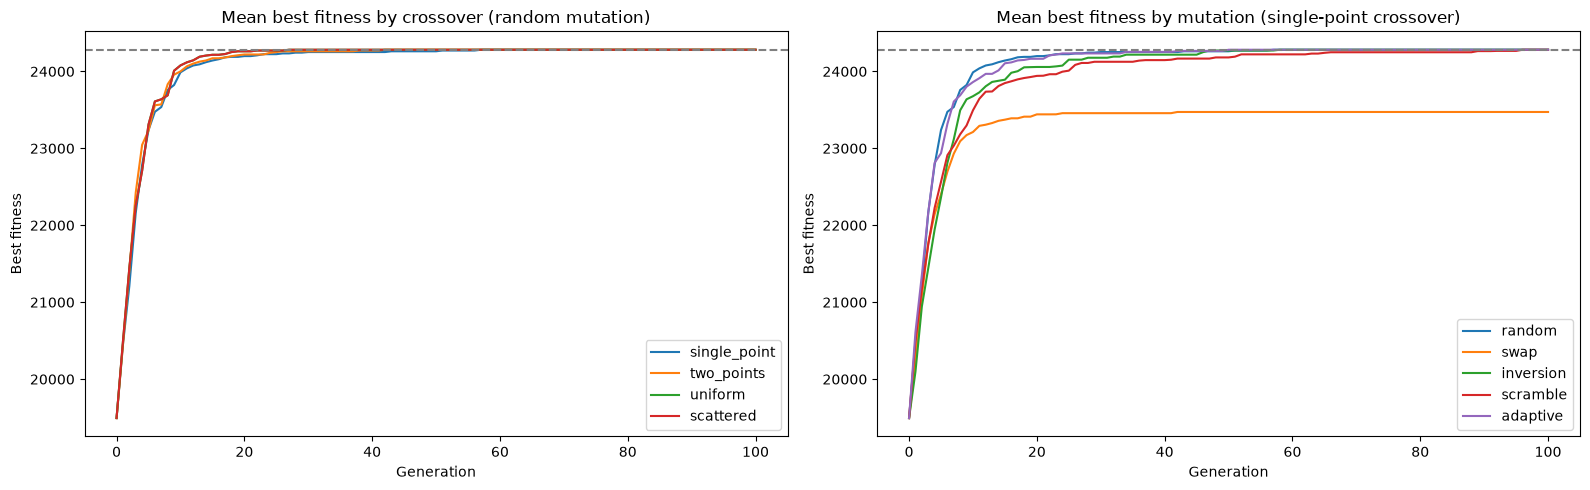

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for crossover_type in CROSSOVER_TYPES:
  curves = [run_ga(seed, crossover_type=crossover_type).best_solutions_fitness for seed in SEEDS]
  axes[0].plot(np.mean(curves, axis=0), label=crossover_type)
axes[0].set_title('Mean best fitness by crossover (random mutation)')

for mutation_type in MUTATION_TYPES:
  curves = [run_ga(seed, mutation_type=mutation_type).best_solutions_fitness for seed in SEEDS]
  axes[1].plot(np.mean(curves, axis=0), label=mutation_type)
axes[1].set_title('Mean best fitness by mutation (single-point crossover)')

for ax in axes:
  ax.axhline(OPTIMAL_VALUE, color='gray', linestyle='--')
  ax.set_xlabel('Generation')
  ax.set_ylabel('Best fitness')
  ax.legend()

plt.tight_layout()
plt.show()

## 8. Other parameters: parent selection, mutation rate, population size

In [62]:
selection_rows = []
for selection in ['sss', 'rws', 'sus', 'rank', 'random', 'tournament']:
  runs = [run_ga(seed, parent_selection_type=selection) for seed in SEEDS]
  selection_rows.append({'parent selection': selection, **summarize_runs(runs)})

pd.DataFrame(selection_rows).set_index('parent selection').round(2)

,"optimum found, %",mean best value,worst best value,mean generation of best
parent selection,,,,
sss,100.0,24281.55,24281.55,20.50
rws,95.0,24271.55,24081.56,29.15
sus,100.0,24281.55,24281.55,35.10
rank,5.0,23231.52,21282.55,45.85
random,60.0,24201.55,24081.56,46.40
tournament,100.0,24281.55,24281.55,17.95


In [67]:
rate_rows = []
for percent in [7, 15, 25, 35, 50]:
  runs = [run_ga(seed, mutation_percent_genes=percent) for seed in SEEDS]
  rate_rows.append({
    'mutation genes, %': percent,
    'mutated genes': max(1, int(percent * N_PRODUCTS / 100)),
    **summarize_runs(runs),
  })

pd.DataFrame(rate_rows).set_index('mutation genes, %').round(2)

,mutated genes,"optimum found, %",mean best value,worst best value,mean generation of best
"mutation genes, %",,,,,
7,1,100.0,24281.55,24281.55,20.50
15,2,90.0,24256.59,23982.26,40.45
25,3,55.0,24169.66,23851.65,44.70
35,4,15.0,23940.39,23281.56,48.75
50,7,5.0,23612.67,22673.61,49.10


In [73]:
size_rows = []
for size, generations in [(10, 50), (10, 100), (20, 50), (20, 100), (40, 50), (40, 100)]:
  runs = [
    run_ga(seed, sol_per_pop=size, num_parents_mating=size // 2, num_generations=generations)
    for seed in SEEDS
  ]
  size_rows.append({
    'population': size,
    'generations': generations,
    'fitness evaluations': size * (generations + 1),
    **summarize_runs(runs),
  })

pd.DataFrame(size_rows).round(2)

,population,generations,fitness evaluations,"optimum found, %",mean best value,worst best value,mean generation of best
0,10,50,510,95.0,24271.55,24081.56,21.25
1,10,100,1010,100.0,24281.55,24281.55,24.60
2,20,50,1020,90.0,24261.55,24081.56,17.15
3,20,100,2020,100.0,24281.55,24281.55,20.50
4,40,50,2040,100.0,24281.55,24281.55,10.10
5,40,100,4040,100.0,24281.55,24281.55,10.10


## 9. Best parameter set

In [84]:
LARGE_POPULATION: dict[str, Any] = {'sol_per_pop': 40, 'num_parents_mating': 20, 'num_generations': 50}
candidates: dict[str, dict[str, Any]] = {
  'single_point + random': {'crossover_type': 'single_point', 'mutation_type': 'random'},
  'two_points + random': {'crossover_type': 'two_points', 'mutation_type': 'random'},
  'two_points + adaptive': {'crossover_type': 'two_points', 'mutation_type': 'adaptive'},
  'uniform + random': {'crossover_type': 'uniform', 'mutation_type': 'random'},
  'single_point + swap': {'crossover_type': 'single_point', 'mutation_type': 'swap'},
}

candidate_runs = {
  name: [run_ga(seed, **LARGE_POPULATION, **params) for seed in range(100)]
  for name, params in candidates.items()
}
candidate_summary = pd.DataFrame({name: summarize_runs(runs) for name, runs in candidate_runs.items()}).T
candidate_summary = candidate_summary.sort_values(['optimum found, %', 'mean generation of best'], ascending=[False, True])
candidate_summary.round(2)

,"optimum found, %",mean best value,worst best value,mean generation of best
two_points + adaptive,100.0,24281.55,24281.55,11.08
single_point + random,100.0,24281.55,24281.55,11.56
uniform + random,100.0,24281.55,24281.55,12.27
two_points + random,100.0,24281.55,24281.55,12.32
single_point + swap,47.0,24064.36,21131.56,11.77


In [86]:
best_name = str(candidate_summary.index[0])
best_runs = candidate_runs[best_name]
print('Best parameter set:', best_name, LARGE_POPULATION)

best_ga = best_runs[0]
best_solution, best_fitness, _ = best_ga.best_solution()

print(f'Best price: {best_fitness:.2f}, space: {best_solution @ spaces:.4f} m³')
products.assign(loaded=best_solution.astype(bool)).loc[lambda frame: frame['loaded']]

Best parameter set: two_points + adaptive {'sol_per_pop': 40, 'num_parents_mating': 20, 'num_generations': 50}
Best price: 24281.55, space: 2.9172 m³


,name,space,price,price per m³,loaded
1,Cell phone,0.000009,2199.12,244618465.0,True
2,TV 55,0.400000,4346.99,10867.5,True
3,TV 50',0.290000,3999.90,13792.8,True
4,TV 42',0.200000,2999.00,14995.0,True
5,Notebook A,0.003500,2499.90,714257.1,True
7,Microwave A,0.042400,308.66,7279.7,True
8,Microwave B,0.054400,429.90,7902.6,True
9,Microwave C,0.031900,299.29,9382.1,True
11,Refrigerator C,0.870000,1199.89,1379.2,True
12,Notebook B,0.498000,1999.90,4015.9,True


## Conclusion

- The task is the lecture example: 14 products with volume and price and a 3 m³ truck (all products together take 4.8 m³). A chromosome is a 14-gene binary vector; as in the lecture, the fitness is the total price, or 1 if the volume limit is exceeded.
- Brute force over all 16,384 subsets gives the true optimum: 24,281.55 with 2.917 m³ used - everything except Refrigerator A, Refrigerator B and the Ventilator. The GA found exactly this set; for comparison, the hand-written GA in the lecture stopped at 17,755.
- With the base setup (20 chromosomes, 100 generations, steady-state selection, single-point crossover, random mutation of 10% of genes) the optimum is found in generation 32 of the first run and in 100% of 20 seeded runs.
- Crossover type barely matters here: single-point, two-point, uniform and scattered all reach the optimum in 100% of runs with random, adaptive or inversion mutation; uniform/scattered (identical for binary genes) converge slightly faster (~14 generations vs ~20).
- Mutation type matters much more. Swap mutation only permutes existing genes, so the number of loaded products never changes and 65-75% of runs get stuck (mean ~23,500-24,000). Scramble is slower and misses the optimum in 5% of runs.
- A small mutation rate is best: 1 mutated gene out of 14 gives 100% success, while mutating 7 genes turns the search into random sampling (5% success).
- Rank selection performs poorly (5% success) and random selection only reaches 60%; steady-state, stochastic universal and tournament selection all give 100%.
- A population of 40 with 50 generations (2,040 fitness evaluations, 12% of brute force) finds the optimum in 100% of 100 runs within ~11 generations with any good crossover plus random or adaptive mutation.
- Recommended set: population 40, 20 parents, steady-state or tournament selection, two-point (or any) crossover, random/adaptive mutation of about 1 gene, 50 generations. For 14 products brute force is still cheap, but the GA reaches the optimum with a fraction of the evaluations and scales to product lists where brute force is impossible.